# День 08. Упражнение 05
# Кластеризация

## 0. Импорты

In [26]:
import pandas as pd
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN
from sklearn.cluster import AgglomerativeClustering
import numpy as np



## 1. Предобработка

1. Прочитай файл [`regression.csv`](https://drive.google.com/file/d/1fzOPkuXoxLleOsvNVCT0m-LKxlid33ma/view?usp=sharing) в DataFrame.
2. Удали колонку `pageviews`, мы будем кластеризовать пользователей только по количеству коммитов и их средней разнице.

In [4]:
df = pd.read_csv("../data/regression.csv")
df = df.drop(columns=["pageviews"])
df.head()

,uid,num_commits,AVG(diff)
0,user_1,62,-64.400000
1,user_10,20,-74.800000
2,user_14,61,-159.000000
3,user_17,51,-61.600000
4,user_18,5,-5.666667


## 2. KMeans

1. Ознакомься с документацией и разберись, как работает этот алгоритм.
2. Используй этот алгоритм для создания кластеров с параметрами `random_state=21` и `n_clusters=3`.
3. Визуализируй данные на `scatter plot`.
4. Попробуй разные значения `n_clusters` и посмотри, как изменится твой график.
5. Вычисли `silhouette_score` (см. документацию по метрике).

In [8]:
X = df[["num_commits", "AVG(diff)"]]
k_means = KMeans(random_state=21, n_clusters=3)
k_pred = k_means.fit_predict(X)

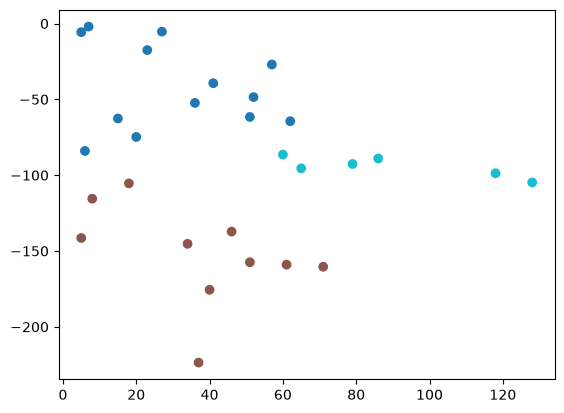

In [10]:
plt.scatter(
    df["num_commits"],
    df["AVG(diff)"],
    c=k_pred,
    cmap="tab10"

)

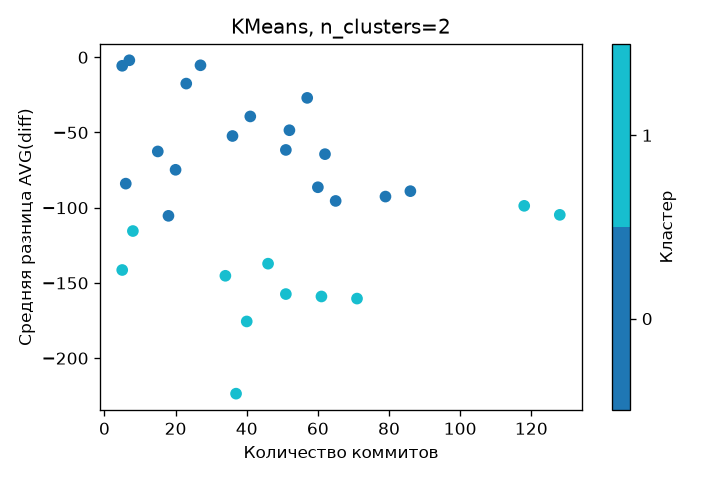

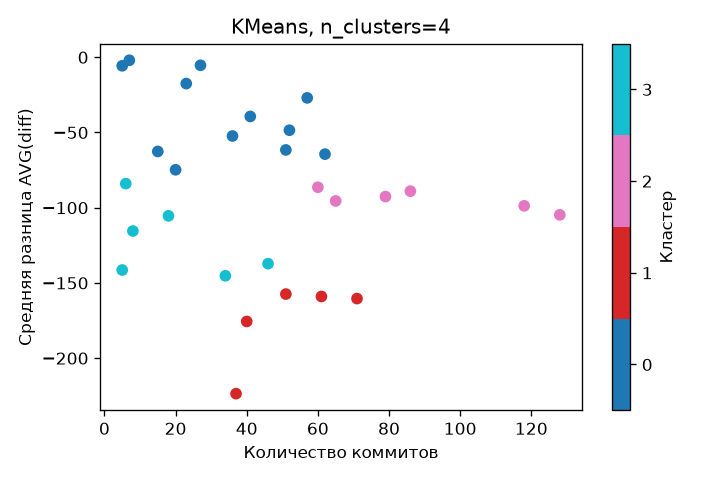

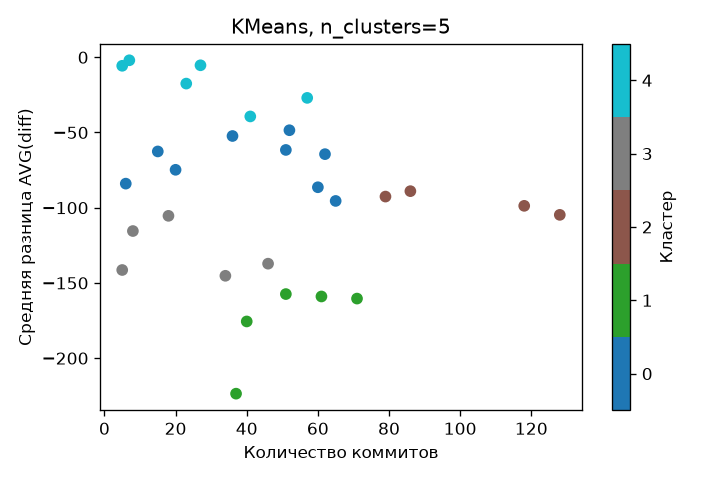

In [ ]:
for n_clusters in [2, 4, 5]:
    test_model = KMeans(random_state=21, n_clusters=n_clusters)
    test_labels = test_model.fit_predict(X)

    plt.figure(figsize=(6,4))
    plt.scatter(
        X["num_commits"], X["AVG(diff)"], c=test_labels,
        cmap=plt.get_cmap("tab10", n_clusters), vmin=-0.5, vmax=n_clusters-0.5
    )
    plt.xlabel("Количество коммитов")
    plt.ylabel("Средняя разница AVG(diff)")
    plt.title(f"KMeans, n_clusters={n_clusters}")
    plt.colorbar(ticks=range(n_clusters), label="Кластер")
    plt.tight_layout()
    plt.show()


In [13]:
score = silhouette_score(X, k_pred)
print(score)

0.4454402135233297


## 3. DBSCAN

1. Ознакомься с документацией и разберись, как работает этот алгоритм.
2. Используй этот алгоритм для создания кластеров с параметрами `eps=20` и `min_samples=2`.
3. Визуализируй данные на `scatter plot`.
4. Попробуй разные значения `eps` и `min_samples` и посмотри, как изменится твой график.
5. Вычисли `silhouette_score` (см. документацию по метрике).

[ 0  1  2  0  3  4  5  5  5  6  7  3  5  0  8  0  7 -1 -1  1 -1  0  8  2
  4 -1  1  6  2]


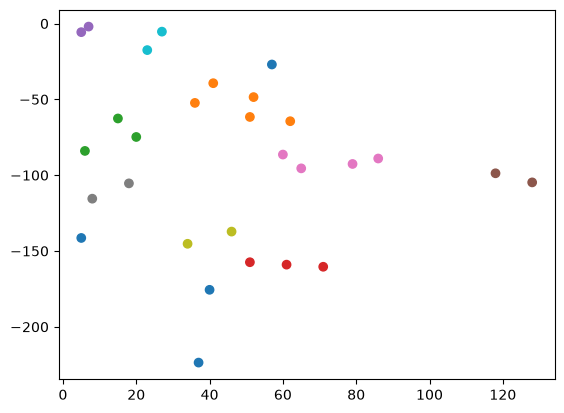

In [18]:
dbscan = DBSCAN(eps=20,min_samples=2)
dbscan_pred = dbscan.fit_predict(X)
print(dbscan_pred)
plt.scatter(
    df["num_commits"],
    df["AVG(diff)"],
    c=dbscan_pred,
    cmap="tab10"
)

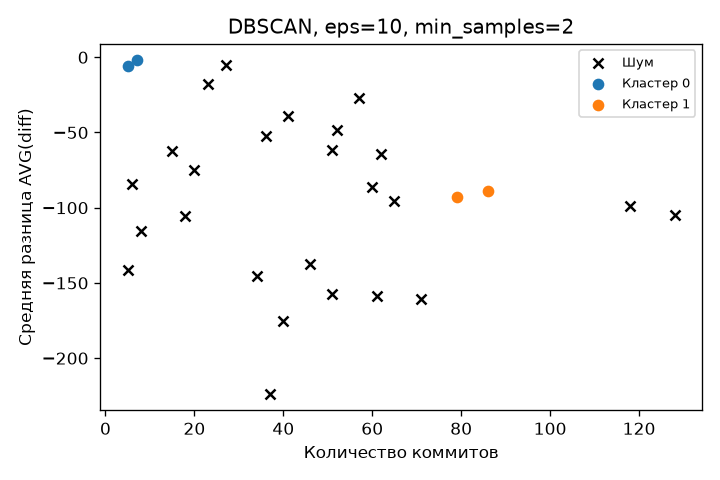

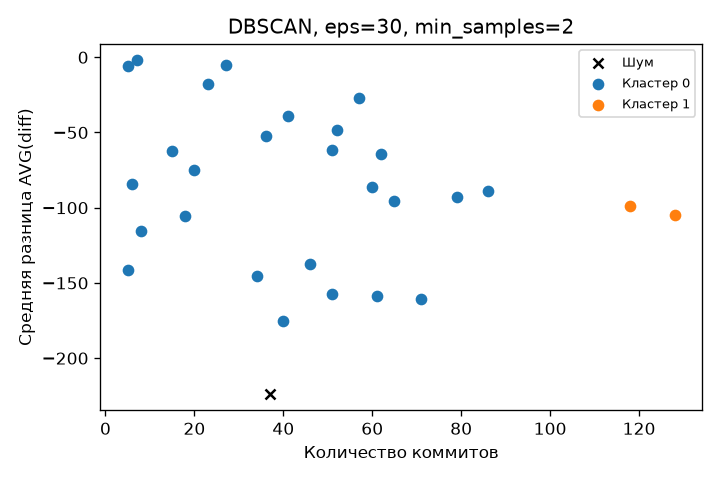

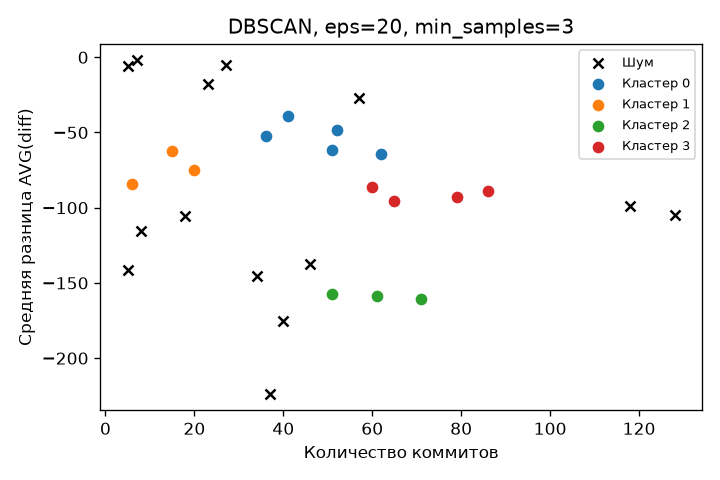

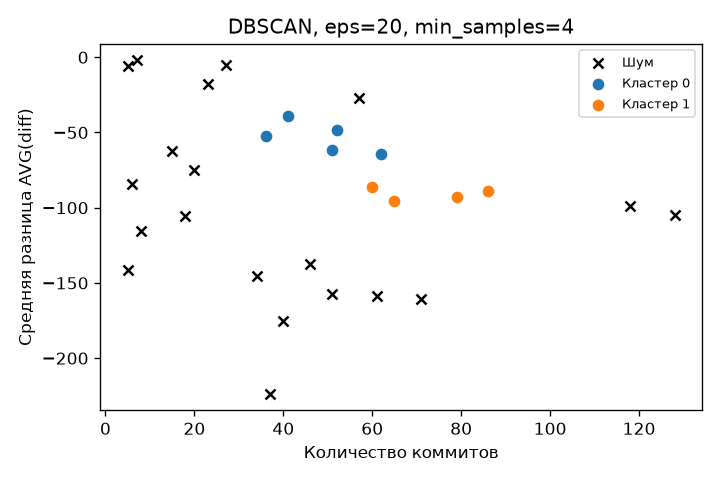

In [ ]:
for eps, min_samples in [(10, 2), (30, 2), (20, 3), (20, 4)]:
    test_dbscan = DBSCAN(eps=eps, min_samples=min_samples)
    test_labels = test_dbscan.fit_predict(X)

    plt.figure(figsize=(6,4))
    for label in sorted(set(test_labels)):
        group = X.loc[test_labels == label]
        if label == -1:
            plt.scatter(group["num_commits"], group["AVG(diff)"], color="black", marker="x", label="Шум")
        else:
            plt.scatter(group["num_commits"], group["AVG(diff)"], label=f"Кластер {label}")
    plt.xlabel("Количество коммитов")
    plt.ylabel("Средняя разница AVG(diff)")
    plt.title(f"DBSCAN, eps={eps}, min_samples={min_samples}")
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


In [20]:
dbscan_sc = silhouette_score(X, dbscan_pred)
print(dbscan_sc)

0.38339641455696616


## 4. Иерархическая кластеризация (AgglomerativeClustering)

1. Используй этот алгоритм для создания кластеров с параметром `n_clusters=5`.
2. Визуализируй данные на `scatter plot`.
3. Попробуй разные значения `n_clusters` и посмотри, как изменится твой график.
4. Вычисли `silhouette_score`.
5. Визуализируй `dendrogram`.

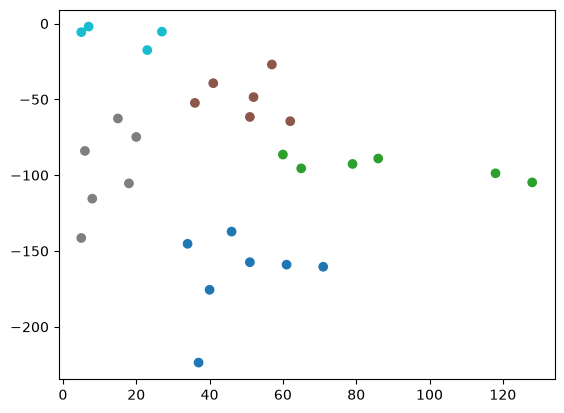

In [24]:
algo = AgglomerativeClustering(n_clusters=5)
al_pred = algo.fit_predict(X)
plt.scatter(
    df["num_commits"],
    df["AVG(diff)"],
    c=al_pred,
    cmap="tab10"
)

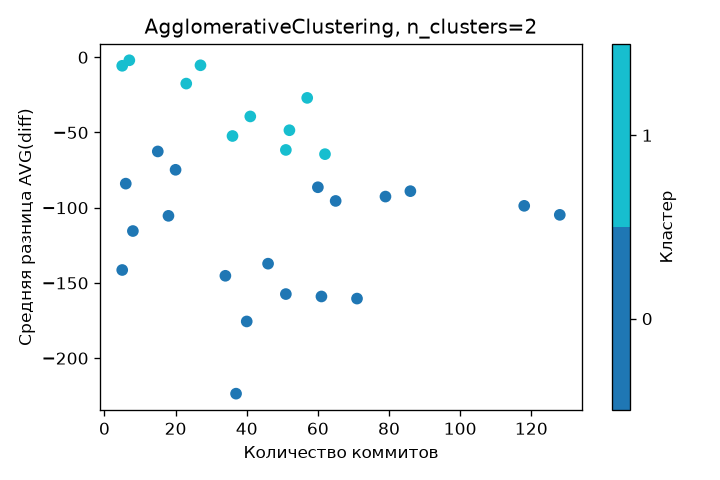

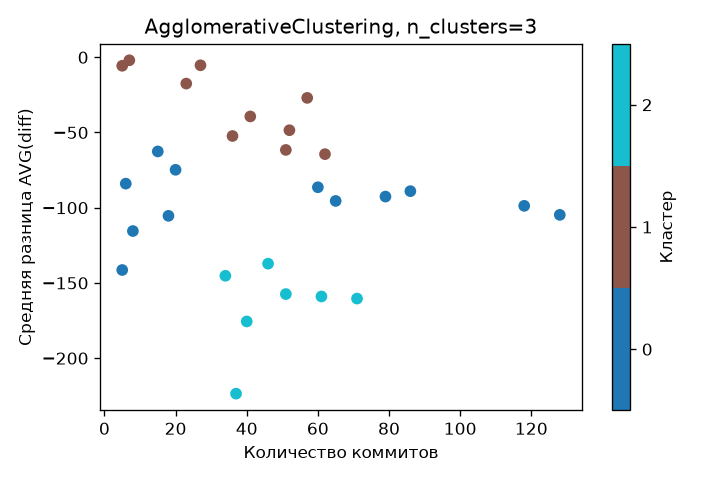

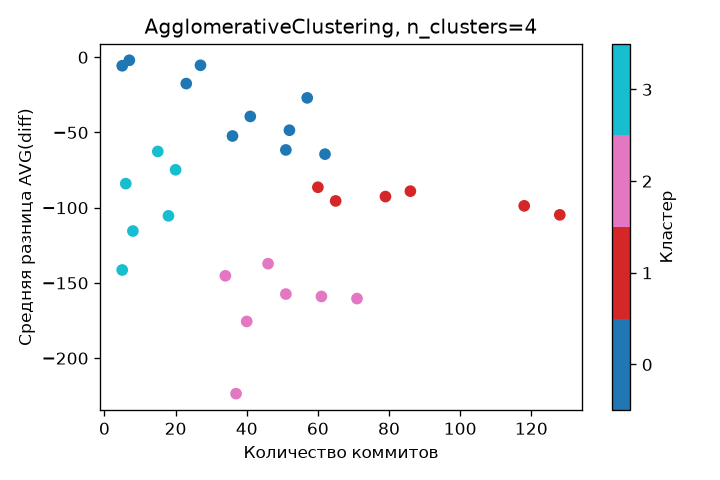

In [ ]:
for n_clusters in [2, 3, 4]:
    test_algo = AgglomerativeClustering(n_clusters=n_clusters)
    test_al_pred = test_algo.fit_predict(X)

    plt.figure(figsize=(6,4))
    plt.scatter(
        X["num_commits"], X["AVG(diff)"], c=test_al_pred,
        cmap=plt.get_cmap("tab10", n_clusters), vmin=-0.5, vmax=n_clusters-0.5
    )
    plt.xlabel("Количество коммитов")
    plt.ylabel("Средняя разница AVG(diff)")
    plt.title(f"AgglomerativeClustering, n_clusters={n_clusters}")
    plt.colorbar(ticks=range(n_clusters), label="Кластер")
    plt.tight_layout()
    plt.show()


In [25]:
al_score = silhouette_score(X, al_pred)
print(al_score)


0.46383015199381467


## 5. Функция

Напиши функцию, которая:
1. Принимает аргументы: класс модели кластеризации, её параметры, имя параметра для оптимизации и диапазон значений этого параметра.
2. Перебирает разные значения из заданного диапазона и вычисляет `silhouette_score` для каждого значения.
3. Определяет лучшее значение параметра в диапазоне.
4. Возвращает два подграфика:

- первый показывает, как `silhouette_score` меняется в зависимости от значения параметра;
- второй визуализирует данные на `scatter plot` с использованием модели кластеризации с лучшим найденным значением параметра.

In [ ]:
def vizscore(modclass, params, optname, optparams):
    current_params = params.copy()
    mx_ac = float("-inf")
    best_m = None
    best_labels = None
    acs = []
    for i in range(len(optparams)):
        current_params[optname] = optparams[i]
        model = modclass(**current_params)
        mod_pred = model.fit_predict(X)
        if not 2 <= len(set(mod_pred)) < len(X):
            print(f"Для {optparams[i]} silhouette_score вычислить нельзя, пропускаем")
            acs.append([float("nan"), optparams[i]])
            continue
        ac = silhouette_score(X, mod_pred)
        acs.append([ac, optparams[i]])
        print(f"silhouette_score для {optparams[i]} - {ac}")
        if ac > mx_ac:
            mx_ac = ac
            best_m = optparams[i]
            best_labels = mod_pred
    if best_labels is None:
        print("Нет подходящего разбиения для вычисления silhouette_score")
        return None

    print(f"Лучший параметр - {best_m}")

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9))

    # Как меняется ac в зависимости от параметра

    param_values = [row[1] for row in acs]
    scores = [row[0] for row in acs]
    ax1.plot(param_values, scores, marker="o")
    ax1.set_title(modclass.__name__)
    ax1.set_xlabel(optname)
    ax1.set_ylabel("silhouette_score")

    #Второй график, 
    ax2.scatter(
        X["num_commits"],
        X["AVG(diff)"],
        c=best_labels,
        cmap="tab10"
    )
    ax2.set_xlabel("num_commits")
    ax2.set_ylabel("AVG(diff)")
    ax2.set_title(f"Лучшее разбиение: {optname}={best_m}")

    fig.tight_layout()
    return fig, (ax1, ax2)


silhouette_score для 2 - 0.4194920562377423
silhouette_score для 3 - 0.4454402135233297
silhouette_score для 4 - 0.41503879936268956
silhouette_score для 5 - 0.3521030626149593
silhouette_score для 6 - 0.3954350435152892
silhouette_score для 7 - 0.3963747661984397
silhouette_score для 8 - 0.48638087320227846
silhouette_score для 9 - 0.4537667044117413
silhouette_score для 10 - 0.42633476071518833
Лучший параметр - 8


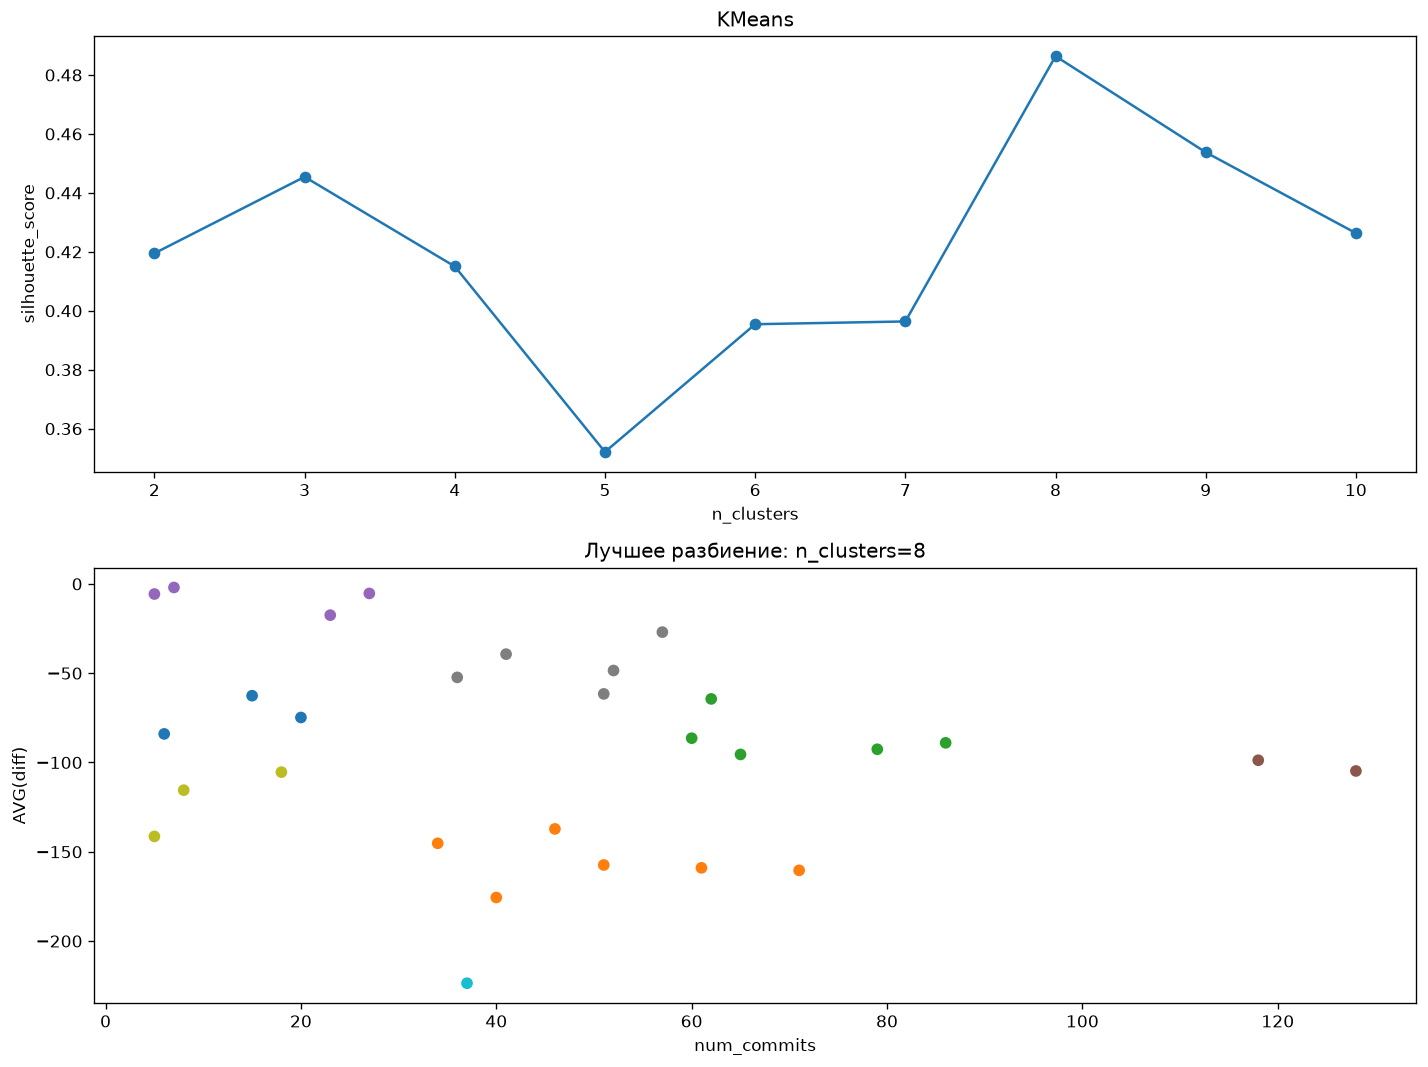

In [ ]:
vizscore(KMeans, {"random_state": 21}, "n_clusters", range(2, 11))
plt.show()


silhouette_score для 5 - 0.2468241360324413
silhouette_score для 10 - -0.07923479818777455
silhouette_score для 15 - 0.34698448575812263
silhouette_score для 20 - 0.38339641455696616
silhouette_score для 25 - 0.34388947016930727
silhouette_score для 30 - 0.19881722125199422
silhouette_score для 35 - 0.3659855186711519
silhouette_score для 40 - 0.3659855186711519
silhouette_score для 45 - 0.3659855186711519
Для 50 silhouette_score вычислить нельзя, пропускаем
Для 55 silhouette_score вычислить нельзя, пропускаем
Для 60 silhouette_score вычислить нельзя, пропускаем
Лучший параметр - 20


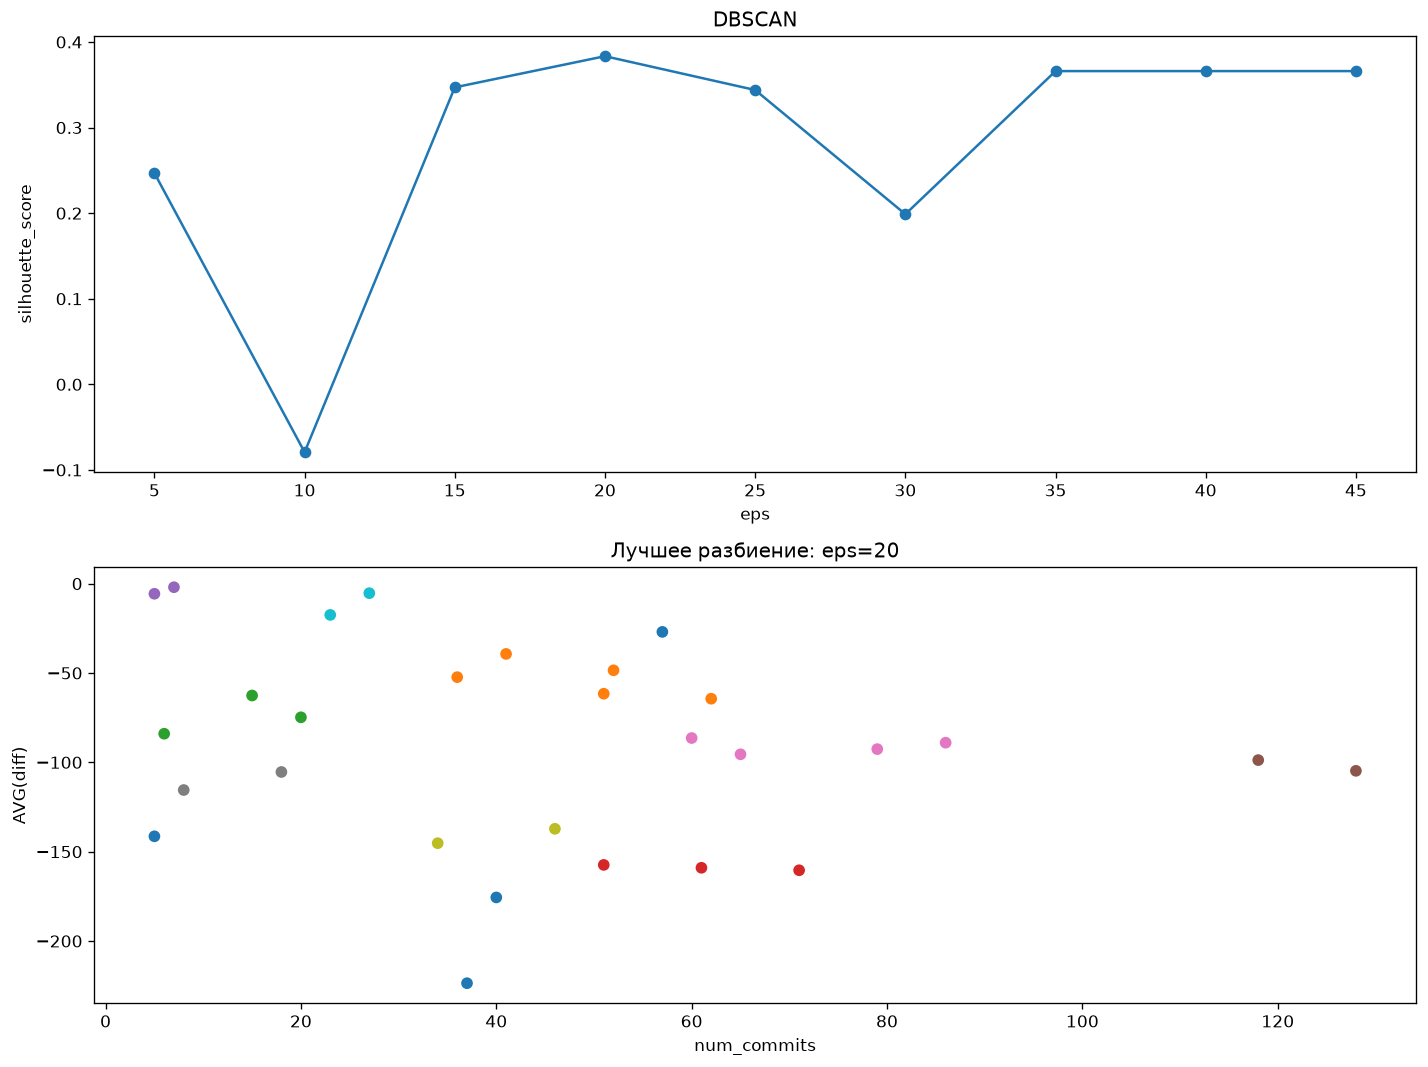

In [ ]:
# Метрика учитывает метку шума -1 как отдельную группу.
vizscore(DBSCAN, {"min_samples": 2}, "eps", range(5, 61, 5))
plt.show()


silhouette_score для 2 - 0.35902490572221984
silhouette_score для 3 - 0.3390493703444805
silhouette_score для 4 - 0.4448362750283643
silhouette_score для 5 - 0.46383015199381467
silhouette_score для 6 - 0.4527145606287827
silhouette_score для 7 - 0.4865808853184314
silhouette_score для 8 - 0.5077985556562201
silhouette_score для 9 - 0.47576869039147557
silhouette_score для 10 - 0.4311939305393331
Лучший параметр - 8


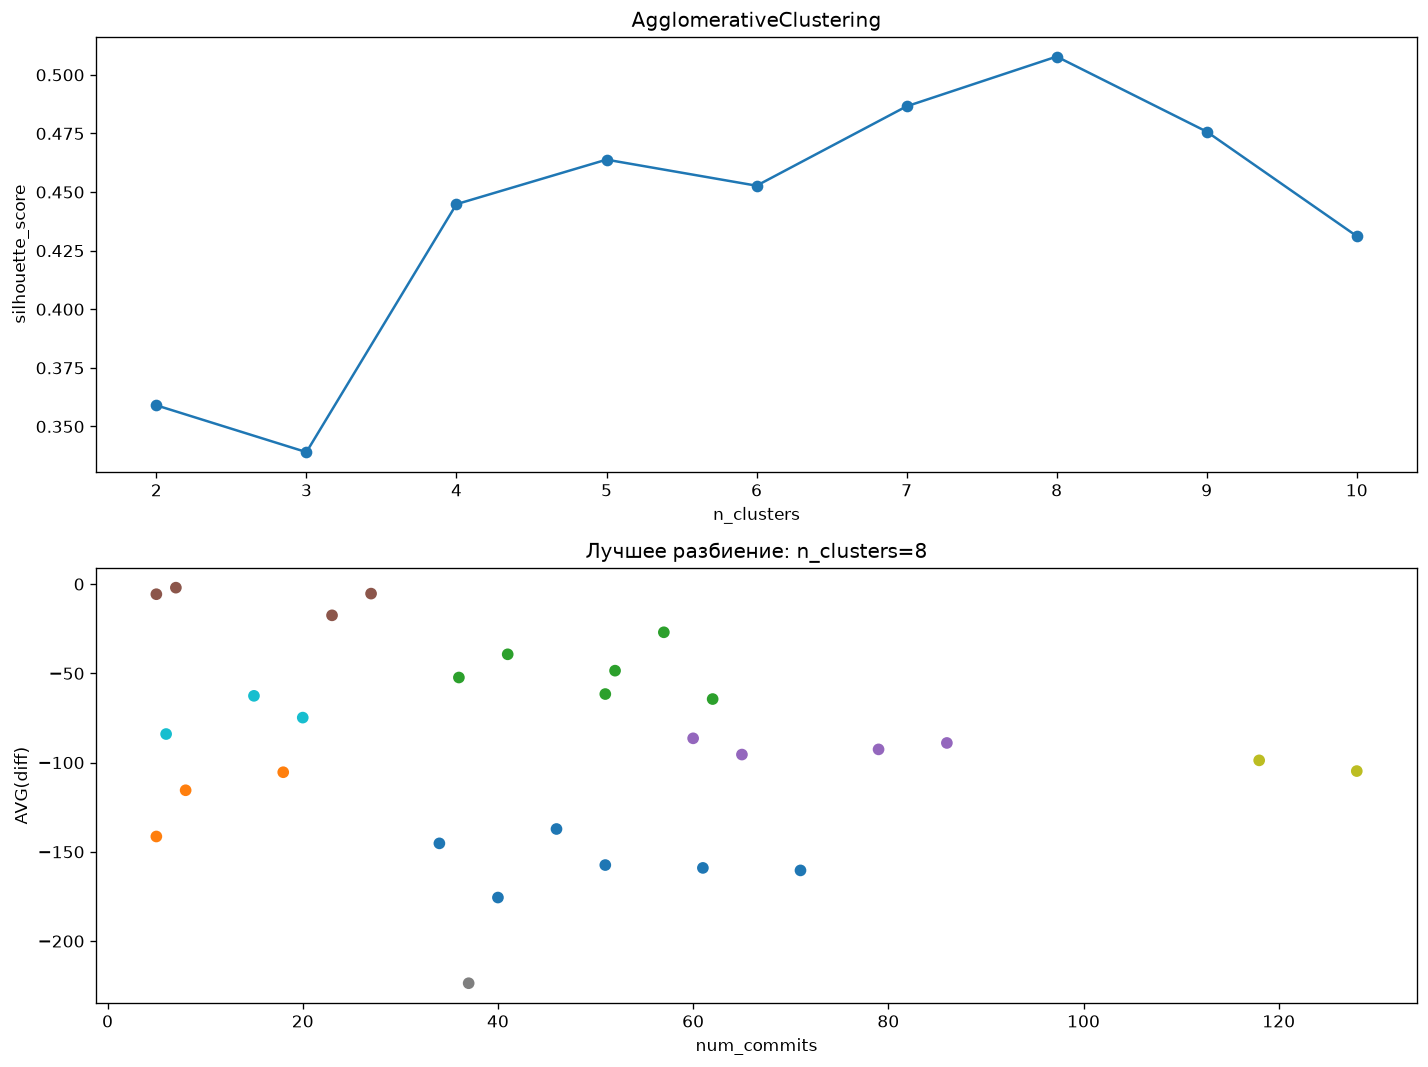

In [ ]:
vizscore(AgglomerativeClustering, {}, "n_clusters", range(2, 11))
plt.show()
